# Store Sales 进阶版：基于预测起点的共享神经网络与模型融合
姓名：________　学号：________

本报告在基础课程作业上增加起点建样本、最新历史统计、未来促销、共享嵌入、MLP/Mixer、季节残差、消融、多种子和融合实验。

**执行范围说明：** 当前环境为 CPU。本轮测得网络训练速度后，采用宽度32、基础组每轮随机4096条窗口、最多8轮，追加三层Mixer每轮8192条、最多16轮的受限实验；基础组内部比较2/8轮、加长组比较2/16轮后再重训。保留112天历史、16天输出、六组结构、四个外层窗口和多个种子。它是实际完成的 CPU 进阶实验，不代表计划中的更大GPU训练已完成。原固定窗口已经观察过，属于回归检查，不称新盲测。Kaggle尚无真实提交回执。

耗时、参数量与分数均由保存的实际实验读取。默认报告加载已运行产物；要重新计算，执行下一单元格中的开关。

In [1]:
from pathlib import Path
import sys,json,subprocess,inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd();OUT=ROOT/'outputs/advanced'
sys.path.insert(0,str(ROOT/'src'))
RUN_EXPERIMENTS=False
if RUN_EXPERIMENTS:subprocess.run([sys.executable,'scripts/run_advanced.py'],check=True)
metrics=pd.read_csv(OUT/'metrics.csv');selection=json.loads((OUT/'selection.json').read_text())
config=json.loads((OUT/'execution_config.json').read_text())
display_name=('B0' if selection['winner']=='B0' else selection['tree_model'] if selection['weight_tree']==1 else selection['network_kind'] if selection['weight_tree']==0 else selection['winner'])
dev=['2016-08-16','2017-04-16','2017-06-15','2017-07-15']
leader=pd.read_csv(OUT/'leaderboard.csv')
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2})
FIG=OUT/'figures';FIG.mkdir(exist_ok=True)
def fig(name):
 plt.tight_layout();plt.savefig(FIG/(name+'.png'),bbox_inches='tight');plt.show();plt.close()
def oof(name,date):
 suffix=str((pd.Timestamp(date)-pd.Timedelta(days=1)).date());p=OUT/f'oof_{name}_{suffix}.csv'
 return pd.read_csv(p if p.exists() else Path(str(p)+'.gz'))
display(pd.Series(config).to_frame('实际运行配置'))


,实际运行配置
device,cpu
width,32
batch_size,256
inner_mode,budget
windows_per_epoch,4096
epoch_candidates,"[2, 8]"
max_epochs,8
history,112
horizon,16
seed,42


## 1. 研究目标、数据与验证协议
54家商店、33个品类，共1782条日销量序列。每个起点T输入最近112天历史，使用未来16天已知促销与日历，预测T+1…T+16。历史销量、交易笔数及油价只取截至T的记录，地震等不可预知事件不作为已知未来输入。

四个开发窗口：2016-08-16—08-31、2017-04-16—05-01、2017-06-15—06-30、2017-07-15—07-30。最后用2017-07-31—08-15回归检查。内层窗口用于选择轮数，外层标签不参与训练或早停。主指标为逐记录RMSLE，辅助报告MAE、RMSE、R²。

In [2]:
tests=json.loads((OUT/'data_tests.json').read_text());display(pd.Series(tests).to_frame('检查'))
verified=json.loads((OUT/'independent_verification.json').read_text())
display(pd.DataFrame(verified['verified_experiments']).head(10))
old=metrics.loc[(metrics.model=='B0')&metrics.date.isin(dev),'RMSLE']
best=leader.iloc[0]
gain=1-best.pooled_RMSLE/np.sqrt(np.mean(old**2))
r=metrics.loc[(metrics.model=='FINAL')&(metrics.date=='2017-07-31')].iloc[0]
display(Markdown(f'**实际结果摘要：** 开发阶段选择 **{display_name}**，四窗合并RMSLE为 **{best.pooled_RMSLE:.5f}**，相对原模型改善 **{gain:.2%}**。锁定后固定回归窗口RMSLE为 **{r.RMSLE:.5f}**。这些均为本地结果，不是Kaggle线上分数。'))


,检查
future_sales_invariance,True
known_future_promotion_reaches_input,True
all_training_labels_available,True
missing_christmas_masked,True
real_zero_sales_retained,True


,model,date,rmsle_recomputed,labels_match
0,B0,2016-08-16,0.730243,True
1,B0,2017-04-16,0.521731,True
2,B0,2017-06-15,0.393873,True
3,B0,2017-07-15,0.401066,True
4,B0,2017-07-31,0.426108,True
5,mlp,2017-06-15,0.428602,True
6,mlp,2017-07-15,0.421271,True
7,mixer2,2017-06-15,0.427048,True
8,mixer2,2017-07-15,0.424561,True
9,mixer3,2017-06-15,0.420120,True


**实际结果摘要：** 开发阶段选择 **B3**，四窗合并RMSLE为 **0.50178**，相对原模型改善 **5.23%**。锁定后固定回归窗口RMSLE为 **0.40603**。这些均为本地结果，不是Kaggle线上分数。

## 2. 预测起点样本与增强树
树模型把每个起点展开为16个预测步长，使用截至T的最新1/7/14/28/56天信息、均值、波动、零销量比例、门店和品类总量、历史同星期锚点，以及未来已知促销、日历和364天前参照。训练标签末日必须不晚于该折截止日。

B0是冻结的基础模型；B1使用2015年以来的起点样本；B1_2016单独检验训练窗；B2增加截至起点的油价和交易信息；B3比较600轮、63直方图bins、全列采样的高效参数组。两组近期窗口用于初筛树配置，将候选B1和B3扩展到完整四窗，按四窗结果锁定最终模型。

date,2016-08-16,2017-04-16,2017-06-15,2017-07-15,window_count,available_windows_pooled
model,,,,,,
B0,0.73024,0.52173,0.39387,0.40107,4,0.52949
B1,0.69723,0.49266,0.38384,0.38650,4,0.50635
B1_2016,NaN,NaN,0.38250,0.39097,2,0.38676
B2,NaN,NaN,0.38307,0.38734,2,0.38521
B3,0.68418,0.49366,0.38270,0.38582,4,0.50178
mixer2,0.76881,0.74104,0.42705,0.42456,4,0.61295
mixer3,0.76680,0.72005,0.42012,0.42224,4,0.60441
mixer3_long,0.74663,0.67482,0.40516,0.40646,4,0.57927
mixer3_long_seed2026,NaN,NaN,0.40649,0.40316,2,0.40483


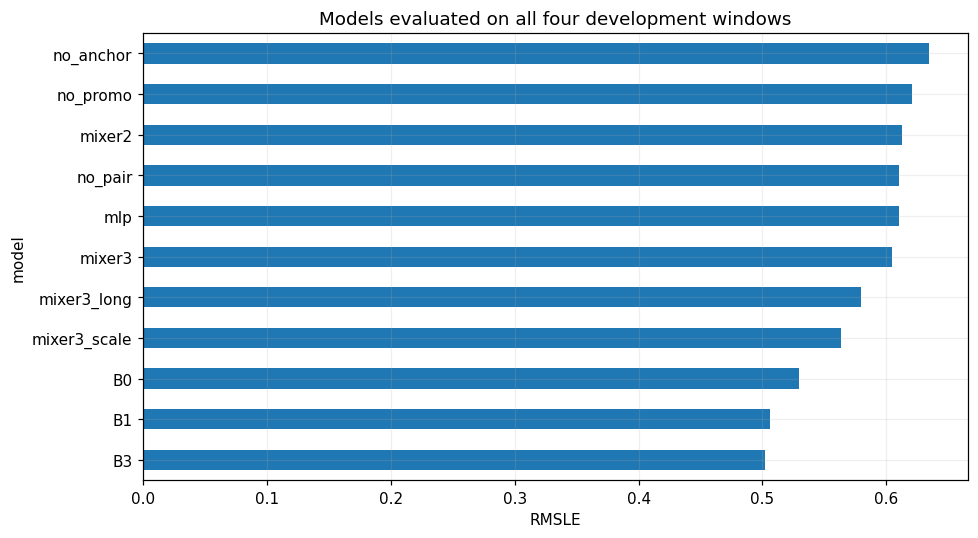

In [3]:
table=metrics.loc[metrics.date.isin(dev)].pivot(index='model',columns='date',values='RMSLE')
table['window_count']=table.notna().sum(axis=1)
table['available_windows_pooled']=np.sqrt((table[dev]**2).mean(axis=1))
display(table.round(5))
full=table.loc[table.window_count==4].sort_values('available_windows_pooled')
full['available_windows_pooled'].plot.barh(figsize=(9,5));plt.xlabel('RMSLE');plt.title('Models evaluated on all four development windows');fig('01_full_window_comparison')


## 3. 共享多步网络设计
历史包含对数销量、促销、门店与品类总量、历史外生量及观测掩码。上下文归一化只看截至起点的数据，标签保持原log1p尺度。门店、品类和组合嵌入分别为8、8、16维，商店类型及cluster提供静态补充。

Mixer沿时间与特征维混合，带LayerNorm、GELU、Dropout和残差；时间投影将112步历史转换为16步状态，与未来促销/日历、静态及预测步长嵌入一起解码。模型预测季节锚点上的修正量，输出log销量，最后截断非负并expm1还原。基础MLP使用相同输入作为稠密编码对照。额外mixer3_scale分支保留归一化前的均值、尺度与起点原始水平，与mixer3_long按相同训练预算比较；该收益不全归因于混合层。

训练采用log销量MSE、AdamW、梯度裁剪。以下直接展示本轮执行的网络源码。组合嵌入消融采用置零关闭，注册参数量仍包含该表；比较的是信息使用而非模型压缩。CPU耗时受并行阶段资源共享影响，不作为专用硬件速度基准。

```python
class Block(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.n1 = nn.LayerNorm(width)
        self.n2 = nn.LayerNorm(width)
        self.time = nn.Sequential(
            nn.Linear(112, width), nn.GELU(), nn.Dropout(0.1), nn.Linear(width, 112)
        )
        self.feat = nn.Sequential(
            nn.Linear(width, 2 * width),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(2 * width, width),
        )

    def forward(self, x):
        x = x + self.time(self.n1(x).transpose(1, 2)).transpose(1, 2)
        return x + self.feat(self.n2(x))

```

```python
class ForecastNet(nn.Module):
    def __init__(self, sizes, kind="mixer2", width=32):
        self_scale = kind.endswith("_scale")
        kind = kind.removesuffix("_long").removesuffix("_scale")
        super().__init__()
        self.kind = kind
        self.use_scale = self_scale
        self.embed = nn.ModuleList(
            [nn.Embedding(n, d) for n, d in zip(sizes, [8, 8, 16, 4, 4])]
        )
        self.static = nn.Linear(40, 32)
        if kind == "mlp":
            self.encoder = nn.Sequential(
                nn.Flatten(),
                nn.Linear(112 * 8, 128),
                nn.GELU(),
                nn.Linear(128, 16 * width),
            )
        else:
            self.proj = nn.Linear(8, width)
            self.blocks = nn.Sequential(
                *[Block(width) for _ in range(3 if kind == "mixer3" else 2)]
            )
            self.time_out = nn.Linear(112, 16)
        self.future = nn.Linear(15 if self_scale else 12, 16)
        self.horizon = nn.Embedding(16, 8)
        self.head = nn.Sequential(
            nn.Linear(width + 32 + 16 + 8, 2 * width),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(2 * width, 1),
        )
        self.width = width
        nn.init.zeros_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, h, f, s, anchor):
        f = f[:, :, : 15 if self.use_scale else 12].contiguous()
        embeddings = [e(s[:, i]) for i, e in enumerate(self.embed)]
        if self.kind == "no_pair":
            embeddings[2] = embeddings[2] * 0
        static = self.static(torch.cat(embeddings, 1))[:, None].expand(-1, 16, -1)
        if self.kind == "no_promo":
            f = f.clone()
            f[:, :, 0] = 0
        if self.kind == "mlp":
            enc = self.encoder(h).reshape(-1, 16, self.width)
        else:
            enc = self.time_out(self.blocks(self.proj(h)).transpose(1, 2)).transpose(
                1, 2
            )
        horizon = self.horizon(torch.arange(16, device=h.device))[None].expand(
            len(h), -1, -1
        )
        delta = self.head(
            torch.cat([enc, static, self.future(f), horizon], -1)
        ).squeeze(-1)
        return delta if self.kind == "no_anchor" else anchor + delta

```

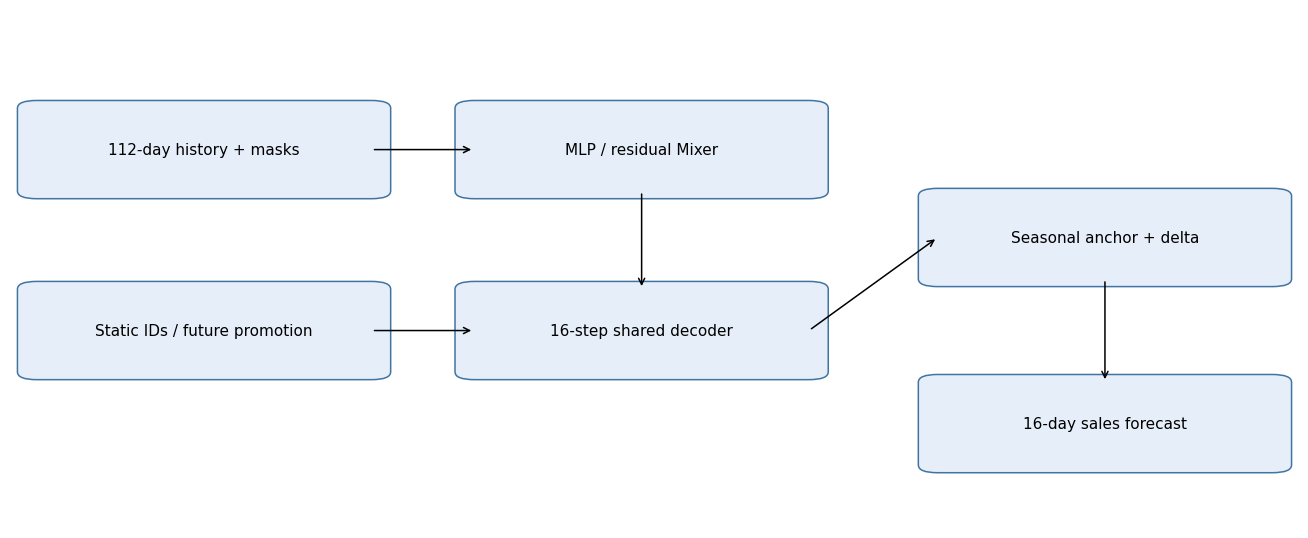

In [4]:
from store_sales.models.mixer import Block,ForecastNet
for cls in [Block,ForecastNet]:display(Markdown('```python'+chr(10)+inspect.getsource(cls)+chr(10)+'```'))
from matplotlib.patches import FancyBboxPatch
f,ax=plt.subplots(figsize=(12,5));ax.axis('off')
boxes=[(.02,.65,'112-day history + masks'),(.02,.3,'Static IDs / future promotion'),(.36,.65,'MLP / residual Mixer'),(.36,.3,'16-step shared decoder'),(.72,.48,'Seasonal anchor + delta'),(.72,.12,'16-day sales forecast')]
for x,y,label in boxes:
 ax.add_patch(FancyBboxPatch((x,y),.26,.16,boxstyle='round,pad=.015',facecolor='#e6eff9',edgecolor='#4274a2'));ax.text(x+.13,y+.08,label,ha='center',va='center',fontsize=10)
for a,b in [((.28,.73),(.36,.73)),((.28,.38),(.36,.38)),((.49,.65),(.49,.46)),((.62,.38),(.72,.56)),((.85,.48),(.85,.28))]:ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->'})
fig('02_architecture')


## 4. 训练曲线、复杂度与消融
六组结构为MLP、两层Mixer、三层Mixer、去组合嵌入、去未来促销、去季节残差。为保证单因素比较，后三项消融均与**两层Mixer**对比。基础六组采用相同CPU抽样及轮数候选预算；额外long与scale组单独报告加长预算；图中不是全数据遍历epoch，准确含义是每轮随机4096条起点—序列窗口。

基础组内层2/8轮、加长三层组2/16轮选择后，回填至外层起点重训；加长组每轮8192样本，其余4096，不将训练量收益归为架构收益；没有用外层真实值提前停止。

,recent_two_windows_RMSLE,difference_vs_mixer2
model,,
mixer2,0.42581,0.00000
mixer3,0.42118,-0.00462
mlp,0.42495,-0.00085
no_anchor,0.43412,0.00831
no_pair,0.42498,-0.00083
no_promo,0.42485,-0.00096


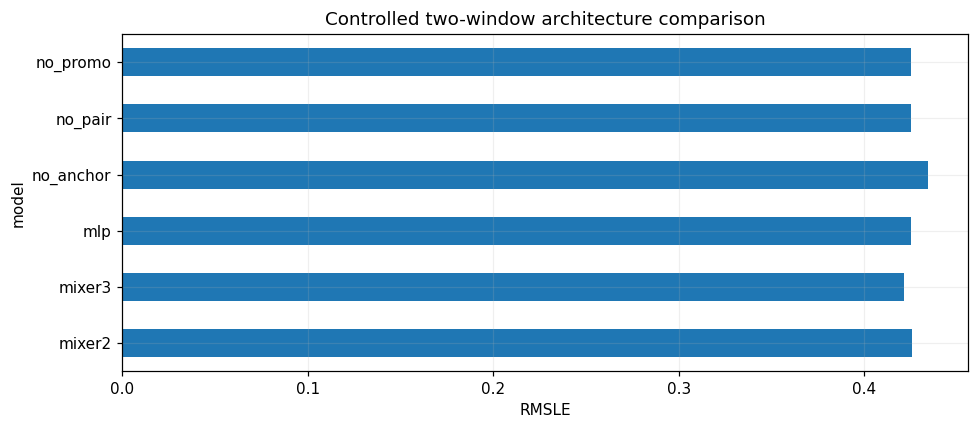

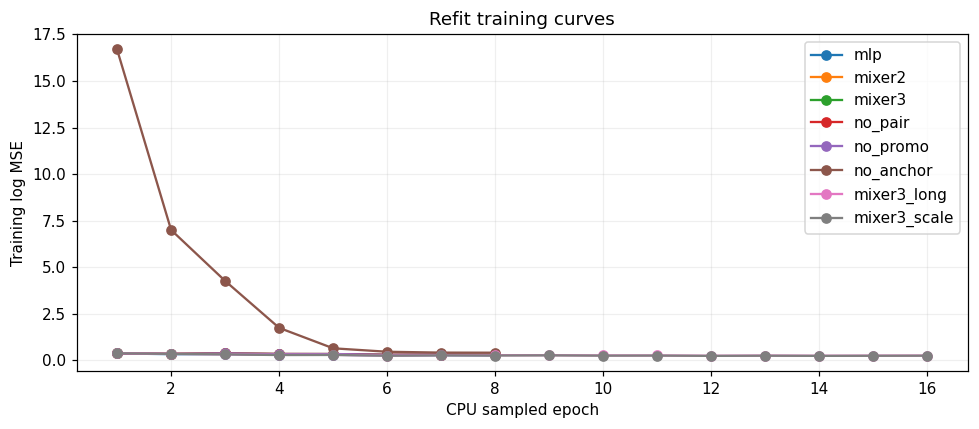

,model,parameters,selected_epochs,train_seconds,windows_per_epoch
0,mlp,217569,8,2.180312,4096
1,mixer2,62065,8,11.880565,4096
2,mixer3,73697,8,15.780065,4096
3,no_pair,62065,8,12.315785,4096
4,no_promo,62065,8,12.053845,4096
5,no_anchor,62065,8,12.407334,4096
6,mixer3_long,73697,16,64.919961,8192
7,mixer3_scale,73745,16,152.927462,8192


In [5]:
kinds=['mlp','mixer2','mixer3','no_pair','no_promo','no_anchor']
recent=metrics.loc[metrics.date.isin(dev[-2:])&metrics.model.isin(kinds)]
abl=recent.groupby('model').RMSLE.apply(lambda x:np.sqrt(np.mean(x*x))).to_frame('recent_two_windows_RMSLE')
abl['difference_vs_mixer2']=abl.recent_two_windows_RMSLE-abl.loc['mixer2','recent_two_windows_RMSLE']
display(abl.round(5));abl.recent_two_windows_RMSLE.plot.barh(figsize=(9,4));plt.xlabel('RMSLE');plt.title('Controlled two-window architecture comparison');fig('03_ablation')
for extra in ['mixer3_long','mixer3_scale']:
 if (OUT/f'training_{extra}_{dev[-1]}.json').exists():kinds=kinds+[extra]
complexity=[]
f,ax=plt.subplots(figsize=(9,4))
for k in kinds:
 data=json.loads((OUT/f'training_{k}_{dev[-1]}.json').read_text())
 curve=pd.DataFrame(data['training_curve']);ax.plot(curve.epoch,curve.train_log_mse,marker='o',label=k)
 complexity.append({'model':k,'parameters':data['parameters'],'selected_epochs':data['selected_epochs'],'train_seconds':curve.seconds.iloc[-1],'windows_per_epoch':data.get('windows_per_epoch',4096)})
ax.set(xlabel='CPU sampled epoch',ylabel='Training log MSE',title='Refit training curves');ax.legend();fig('04_learning_curves')
display(pd.DataFrame(complexity))


## 5. 多种子检验与模型融合
最终神经候选在两个近期窗口用42、2026、3407三个种子复验，并对三份对数预测均值进行同窗检验；该诊断不改变已锁定的最终提交方案。权重为1的融合端点等同纯树，不能声称神经网络贡献了融合增益。仅报告真实波动，不将微小差异视为显著收益。融合在log1p空间进行，使用同一组四窗外层预测，在0、0.25、0.5、0.75、1这五个全局权重中选择，包含单模型端点。

,seed,two_window_RMSLE
0,42,0.407093
1,2026,0.406160
2,3407,0.416314


三种子均值与标准差： 0.40985545005679697 0.0056127397062702014


,date,single_seed_RMSLE,three_seed_mean_RMSLE
0,2017-06-15,0.410524,0.405011
1,2017-07-15,0.403632,0.399616


两窗合并：单种子 0.4070927122783745 ；三种子预测均值 0.4023229303844863


,model,pooled_RMSLE
0,blend_1.0,0.50178
1,B3,0.50178
2,B1,0.50635
3,blend_0.75,0.50720
4,blend_0.5,0.51964
5,B0,0.52949
6,blend_0.25,0.53861
7,mixer3_scale,0.56345
8,blend_0,0.56345
9,mixer3_long,0.57927


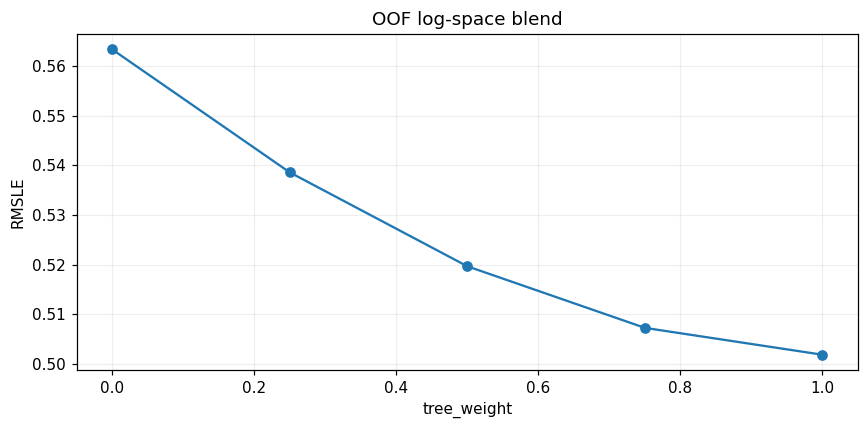

In [6]:
nk=selection['network_kind']
seed_rows=[]
for seed,name in [(42,nk),(2026,nk+'_seed2026'),(3407,nk+'_seed3407')]:
 rr=metrics.loc[(metrics.model==name)&metrics.date.isin(dev[-2:])]
 seed_rows.append({'seed':seed,'two_window_RMSLE':np.sqrt(np.mean(rr.RMSLE**2))})
seed_table=pd.DataFrame(seed_rows);display(seed_table)
print('三种子均值与标准差：',seed_table.two_window_RMSLE.mean(),seed_table.two_window_RMSLE.std())
ensemble=pd.read_csv(OUT/'seed_ensemble_diagnostics.csv');display(ensemble)
print('两窗合并：单种子',np.sqrt(np.mean(ensemble.single_seed_RMSLE**2)),'；三种子预测均值',np.sqrt(np.mean(ensemble.three_seed_mean_RMSLE**2)))
display(leader.round(5))
blend=leader.loc[leader.model.str.startswith('blend_')].copy();blend['tree_weight']=blend.model.str.replace('blend_','',regex=False).astype(float)
blend.sort_values('tree_weight').plot(x='tree_weight',y='pooled_RMSLE',marker='o',legend=False,figsize=(8,4));plt.title('OOF log-space blend');plt.ylabel('RMSLE');fig('05_fusion')


## 6. 锁定后的固定回归窗口
此窗口在基础版已经观察过，只用于新版锁定后的检查。报告逐品类、逐步长和总量曲线，不利用该窗口回流重新选参数。

,model,date,RMSLE,MAE,RMSE,R2
4,B0,2017-07-31,0.42611,76.17997,267.46575,0.95410
57,B3,2017-07-31,0.40603,69.43542,244.97482,0.96149
58,mixer3_scale,2017-07-31,0.45323,73.36765,260.18607,0.95656
59,FINAL,2017-07-31,0.40603,69.43542,244.97482,0.96149


/tmp/ipykernel_6070/4052040277.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  suffix=str((pd.Timestamp(date)-pd.Timedelta(days=1)).date());p=OUT/f'oof_{name}_{suffix}.csv'


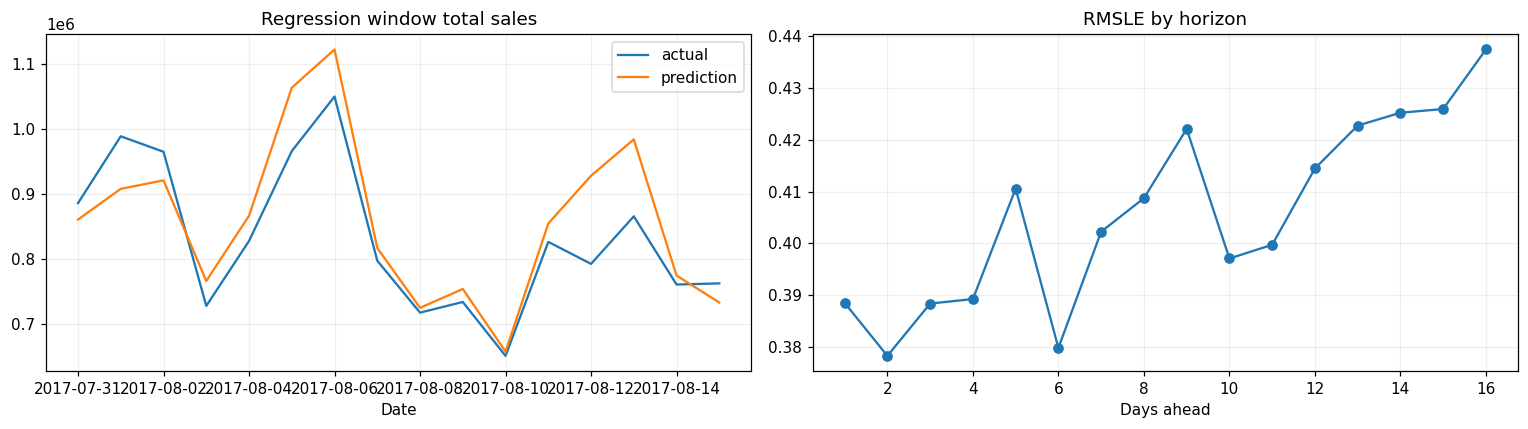

,RMSLE
family,
SCHOOL AND OFFICE SUPPLIES,0.830367
GROCERY II,0.635203
LINGERIE,0.626897
CELEBRATION,0.540931
HARDWARE,0.524179
LADIESWEAR,0.504174
AUTOMOTIVE,0.503249
MAGAZINES,0.500805
SEAFOOD,0.491113


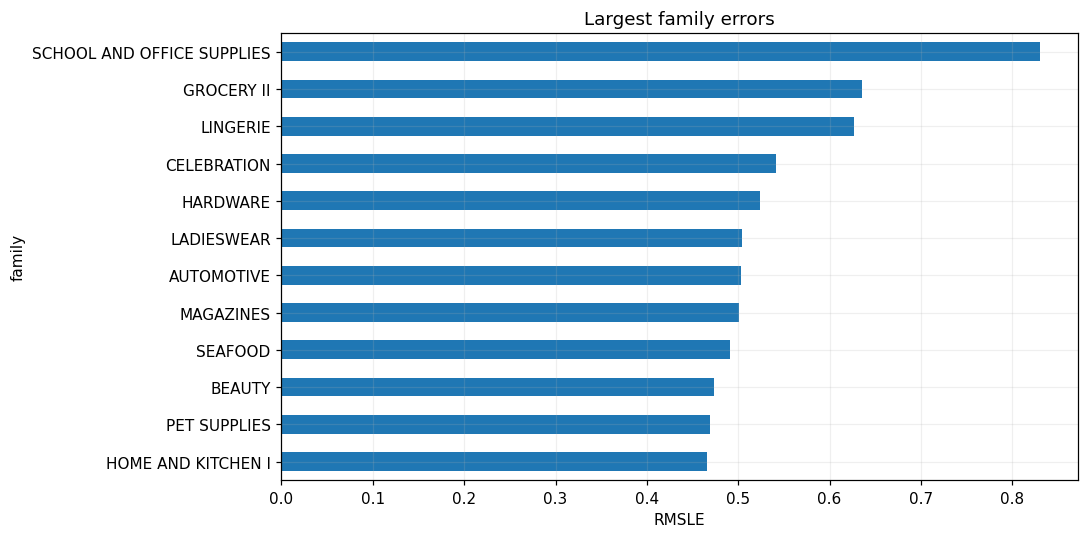

model,B0,B3,relative_improvement
date,,,
2016-08-16,0.730243,0.684182,0.063076
2017-04-16,0.521731,0.493657,0.053809
2017-06-15,0.393873,0.382697,0.028375
2017-07-15,0.401066,0.385820,0.038015


四窗改善数： 4 ；最差窗口相对变化（正数为改善）： 0.02837481171937628


,date,model,group,value,count,RMSLE
943,2017-07-31,B0,zero_sales,positive,24356,0.423795
944,2017-07-31,B0,zero_sales,zero,4156,0.439418
945,2017-07-31,B0,promotion,no_promotion,16031,0.477101
946,2017-07-31,B0,promotion,promotion,12481,0.349873
1050,2017-07-31,FINAL,zero_sales,positive,24356,0.399160
1051,2017-07-31,FINAL,zero_sales,zero,4156,0.444167
1052,2017-07-31,FINAL,promotion,no_promotion,16031,0.445388
1053,2017-07-31,FINAL,promotion,promotion,12481,0.349028


,date,model,group,value,count,RMSLE
980,2017-07-31,FINAL,store_nbr,18,528,0.615651
981,2017-07-31,FINAL,store_nbr,19,528,0.537511
1012,2017-07-31,FINAL,store_nbr,50,528,0.516987
1006,2017-07-31,FINAL,store_nbr,44,528,0.503445
1009,2017-07-31,FINAL,store_nbr,47,528,0.488275
976,2017-07-31,FINAL,store_nbr,14,528,0.477711
988,2017-07-31,FINAL,store_nbr,26,528,0.461806
1010,2017-07-31,FINAL,store_nbr,48,528,0.460670
984,2017-07-31,FINAL,store_nbr,22,528,0.457394
982,2017-07-31,FINAL,store_nbr,20,528,0.454981


In [7]:
reg=metrics.loc[metrics.date=='2017-07-31'];display(reg.round(5))
d=oof('FINAL','2017-07-31');d['actual']=np.expm1(d.actual_log);d['prediction']=np.expm1(d.pred_log);d['sqlog']=(d.actual_log-d.pred_log)**2
f,ax=plt.subplots(1,2,figsize=(14,4))
d.groupby('target_date')[['actual','prediction']].sum().plot(ax=ax[0]);ax[0].set(title='Regression window total sales',xlabel='Date')
d.groupby('h').sqlog.mean().pow(.5).plot(ax=ax[1],marker='o');ax[1].set(title='RMSLE by horizon',xlabel='Days ahead');fig('06_regression')
family=d.groupby('family').sqlog.mean().pow(.5).sort_values(ascending=False);display(family.head(12).to_frame('RMSLE'))
family.head(12).sort_values().plot.barh(figsize=(10,5));plt.xlabel('RMSLE');plt.title('Largest family errors');fig('07_family_errors')
windows=pd.read_csv(OUT/'window_diagnostics.csv')
comparison=windows.loc[windows.date.isin(dev)].pivot(index='date',columns='model',values='RMSLE')
comparison['relative_improvement']=1-comparison[selection['tree_model']]/comparison.B0
display(comparison)
print('四窗改善数：',int(comparison.relative_improvement.gt(0).sum()),'；最差窗口相对变化（正数为改善）：',comparison.relative_improvement.min())
groups=pd.read_csv(OUT/'group_diagnostics.csv')
display(groups.loc[groups.date.eq('2017-07-31') & groups['group'].isin(['zero_sales','promotion'])])
display(groups.loc[groups.date.eq('2017-07-31') & groups.model.eq('FINAL') & groups['group'].eq('store_nbr')].sort_values('RMSLE',ascending=False).head(10))


## 7. 正式测试预测与核验
最终训练截至2017-08-15，只使用已锁定方案。分别导出树、神经和最终预测CSV，每份28512行，ID按官方样例顺序对齐。基础版文件原样保留，进阶版提交文件在outputs/advanced/中。

完整实验的OOF标签已与原始训练数据逐行连接核对，全部指标独立复算。无Kaggle登录提交回执，因此不填写Public Score。

,id,sales
0,3000888,4.249012
1,3000889,0.077316
2,3000890,5.543603
3,3000891,2513.529754
4,3000892,0.075183
5,3000893,407.042937
6,3000894,12.209746
7,3000895,789.005739
8,3000896,826.075946
9,3000897,150.098489


预测行数： 28512 ；线上分数：待真实提交


,count,mean,std,min,25%,50%,75%,max
sales,28512.0,441.519862,1194.364814,0.0,3.848936,28.059313,255.49585,13698.893315


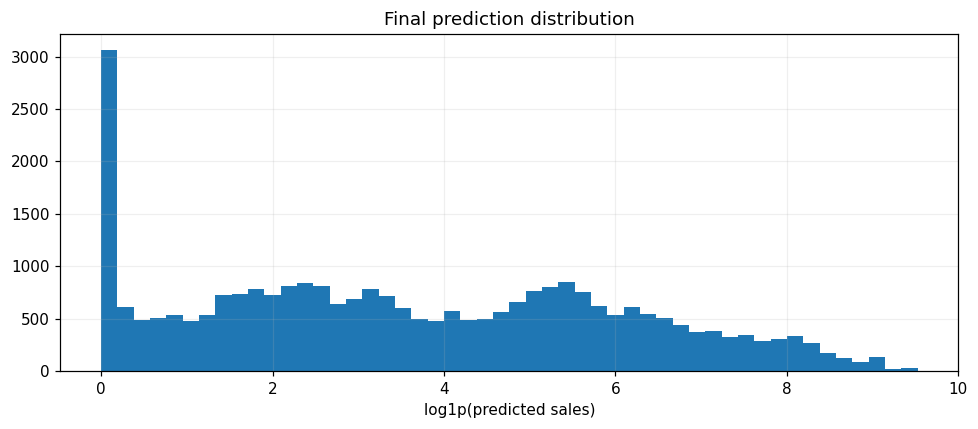

**结论：** 本轮四窗开发RMSLE相对B0改善 **5.23%**，是否达到5%目标：**True**，是否达到固定窗≤0.40挑战线：**False**。固定回归窗口RMSLE为 **0.40603**。最终选择 **B3**。模型复杂度增加并不必然提升精度，最终提交依据同一协议下的实际结果。

In [8]:
sub=pd.read_csv(OUT/'submission_final.csv');display(sub.head(10))
assert sub.shape==(28512,2) and sub.id.is_unique and np.isfinite(sub.sales).all() and sub.sales.ge(0).all()
print('预测行数：',len(sub),'；线上分数：待真实提交')
sub.sales.describe().to_frame().T.pipe(display)
plt.figure(figsize=(9,4));plt.hist(np.log1p(sub.sales),bins=50);plt.xlabel('log1p(predicted sales)');plt.title('Final prediction distribution');fig('08_submission')
display(Markdown(f'**结论：** 本轮四窗开发RMSLE相对B0改善 **{gain:.2%}**，是否达到5%目标：**{gain>=.05}**，是否达到固定窗≤0.40挑战线：**{r.RMSLE<=.40}**。固定回归窗口RMSLE为 **{r.RMSLE:.5f}**。最终选择 **{display_name}**。模型复杂度增加并不必然提升精度，最终提交依据同一协议下的实际结果。'))


## 8. 最终树模型解释与权重复核
增益重要性基于最终训练模型，仅反映模型内部使用情况，不代表因果作用。模型已保存，下面验证重新加载权重后可复现三份提交预测。

,feature,gain
0,rolling_mean_7,1.998846e+08
1,seasonal_anchor,9.370436e+07
2,rolling_mean_14,1.352089e+07
3,origin_lag_0,8.059572e+06
4,future_promotion_log,1.238311e+06
5,family_total_log,1.124420e+06
6,rolling_mean_28,1.004580e+06
7,year_ago_log,8.654275e+05
8,rolling_mean_56,7.354166e+05
9,day_scaled,7.279079e+05


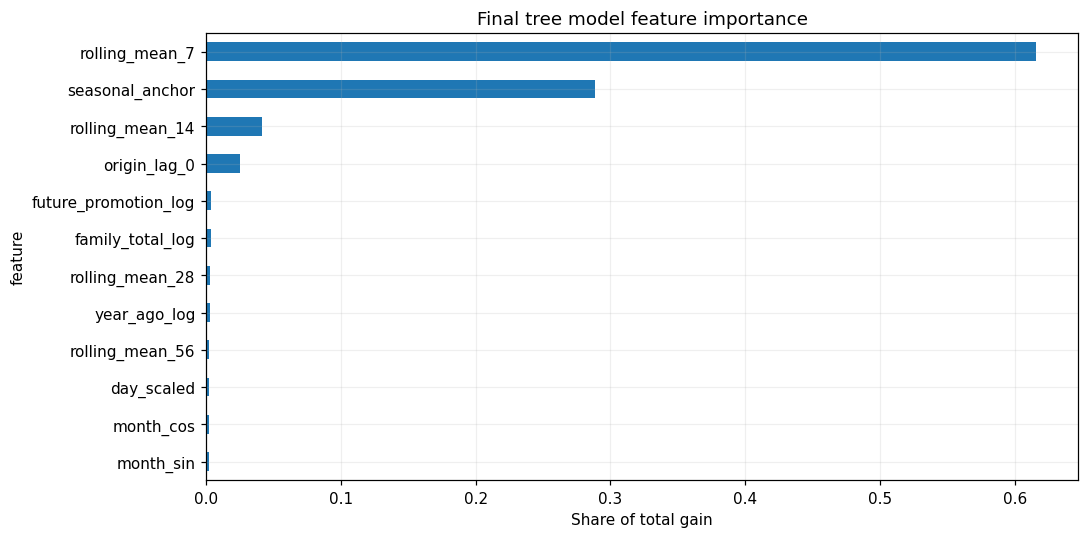

,max log prediction difference
tree,4.440892e-16
network,1.063596e-07
final,4.440892e-16


In [9]:
importance=pd.read_csv(OUT/'feature_importance.csv');display(importance.head(12))
q=importance.head(12).copy();q['gain_share']=q.gain/importance.gain.sum()
q.set_index('feature').gain_share.sort_values().plot.barh(figsize=(10,5));plt.xlabel('Share of total gain');plt.title('Final tree model feature importance');fig('09_feature_importance')
audit=json.loads((OUT/'saved_model_verification.json').read_text());assert audit['weights_reproduce_saved_predictions']
display(pd.Series(audit['max_abs_log_prediction_difference']).to_frame('max log prediction difference'))

## 9. 局限与后续GPU实验
本轮是有明确CPU预算的受限研究（另增加同预算mixer3_scale，将上下文均值、尺度与最新原始水平提供给解码器，与mixer3_long比较）：宽度32而非计划64，基础组每轮4096窗口、2/8轮候选，追加组8192窗口、2/16轮，均非全样本epoch，未采用完整50轮GPU预算。所有结果只适用于这些实际设置，不能据此断言某网络家族的充分训练上限。

MLP/Mixer之间按同一数据、信息和训练预算对比；消融参考两层Mixer。部分模型只在两个窗口初筛，不能直接和四窗指标当作同一排名。四窗用于开发，固定窗口已观察，真实泛化仍需线上评分及更多月份回测。

GPU训练可使用同一模块扩大宽度、样本量与epoch；需要重新生成OOF和锁定选择，而非沿用CPU权重结论。未覆盖的计划项目包括完整GPU预算实测、不同种子预测的集成提交和真实Kaggle回执；GPU配置已实现patience=6，但尚无GPU运行证据；不能标记为已完成。

参考：[TSMixer](https://research.google/pubs/tsmixer-an-all-mlp-architecture-for-time-series-forecasting/)、[TiDE](https://research.google/pubs/long-horizon-forecasting-with-tide-time-series-dense-encoder/)、[Kaggle数据与评价](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/overview)。本网络为任务适配实现，不宣称新的基础架构。
